# 4. Additional studies

Notebook 02 makes the choices that produce the served model: which family, which ensemble,
which hyperparameters, which threshold, then the single test evaluation and the audit. This
notebook holds the studies that feed **no** decision. They exist to answer "did you miss
anything?", and any of them could have overturned a choice made in 02 without being part of
how the model is built.

1. **Does class balancing help?** SMOTE, ADASYN, Tomek links, random over- and
   under-sampling, and loss reweighting.
2. **Do ensembles beat a single tuned model?** Soft, hard and weighted voting, plus stacking.
3. **Were enough model families tried?** AdaBoost, gradient boosting, extra trees, k-nearest
   neighbours, linear SVM.
4. **Does deep learning win on this data?** Four scikit-learn networks and two PyTorch
   networks of increasing depth.
5. **Do sequence models see what the summaries miss?** Five architectures reading the raw
   monthly matrix, then blended with the booster.
6. **Which features are worth including?** The extra columns from notebook 01, the protected
   attributes, re-tuning, segmented scorecards, and automated selection.

Sections 1 to 4 are scored on the **validation** split, so the test split stays reserved for
notebook 02. Sections 5 and 6 report test figures as well, because they are paired across
five independent splits rather than read once. None of these is a candidate for deployment;
the served model is whatever `app.ml.train` builds.

Regenerate with `cd backend` and then `python -m app.ml.experiments`,
`python -m app.ml.sequence_models`, `python -m app.ml.feature_experiments`.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
sys.path.insert(0, str(PROJECT_ROOT / "backend"))

RESULTS = PROJECT_ROOT / "backend" / "artifacts" / "experiment_results.json"
if not RESULTS.exists():
    raise FileNotFoundError(
        f"{RESULTS} not found. Generate it with:\n"
        "    cd backend && python -m app.ml.experiments"
    )

experiments = json.loads(RESULTS.read_text(encoding="utf-8"))
studies = experiments["studies"]

print(f"evaluated on: {experiments['evaluated_on']}")
print(f"rows: {experiments['rows']}")
print(f"studies: {list(studies)}")

def frame(study: str) -> pd.DataFrame:
    return pd.DataFrame(studies[study])[
        ["name", "roc_auc", "pr_auc", "best_f1", "balanced_accuracy", "brier",
         "seconds", "note"]
    ]

REFERENCE = max(
    (r["roc_auc"] for r in studies["ensembling"] if "single tuned" in r["name"]),
    default=np.nan,
)
print(f"\nreference (single tuned LightGBM): {REFERENCE:.4f}")

evaluated on: validation split
rows: {'train': 21000, 'validation': 4500}
studies: ['resampling', 'ensembling', 'model_families', 'neural_networks']

reference (single tuned LightGBM): 0.7831


## 1. Does class balancing help?

The default rate is 22%, which is mild imbalance. Resamplers are fitted on **training rows
only**; the validation split is never resampled, because evaluating on synthetic customers
would measure the sampler rather than the model.

The final row is included deliberately as a counter-example. It applies SMOTE to the whole
dataset and *then* splits, which copies synthetic neighbours of training rows into the test
set. It is labelled invalid and excluded from every ranking.

In [2]:
resampling = frame("resampling").sort_values("roc_auc", ascending=False)
resampling["vs baseline"] = (
    resampling["roc_auc"] - resampling.loc[
        resampling["name"].eq("baseline (no resampling)"), "roc_auc"
    ].iloc[0]
).round(4)
resampling.round(4)

,name,roc_auc,pr_auc,best_f1,balanced_accuracy,brier,seconds,note,vs baseline
8,SMOTE BEFORE split (INVALID),0.9233,0.9403,0.8513,0.8551,0.1062,3.8,not comparable: synthetic rows appear in both ...,0.1404
7,Tomek links cleaning,0.7833,0.5540,0.5414,0.6582,0.1357,3.6,"train became 19,782 rows at 23% default",0.0004
0,baseline (no resampling),0.7829,0.5568,0.5456,0.6482,0.1351,3.0,the deployed configuration,0.0000
1,class_weight=balanced,0.7827,0.5591,0.5453,0.7157,0.1781,2.9,"reweights the loss, does not resample",-0.0002
6,random undersampling,0.7825,0.5442,0.5528,0.7129,0.1829,1.4,"train became 9,290 rows at 50% default",-0.0004
2,scale_pos_weight,0.7816,0.5600,0.5473,0.7135,0.1760,2.5,"reweights the loss, does not resample",-0.0013
5,random oversampling,0.7810,0.5583,0.5447,0.7156,0.1772,3.4,"train became 32,710 rows at 50% default",-0.0019
3,SMOTE,0.7799,0.5506,0.5357,0.6792,0.1405,2.7,"train became 32,710 rows at 50% default",-0.0030
4,ADASYN,0.7777,0.5396,0.5336,0.6744,0.1410,11.2,"train became 33,167 rows at 51% default",-0.0053


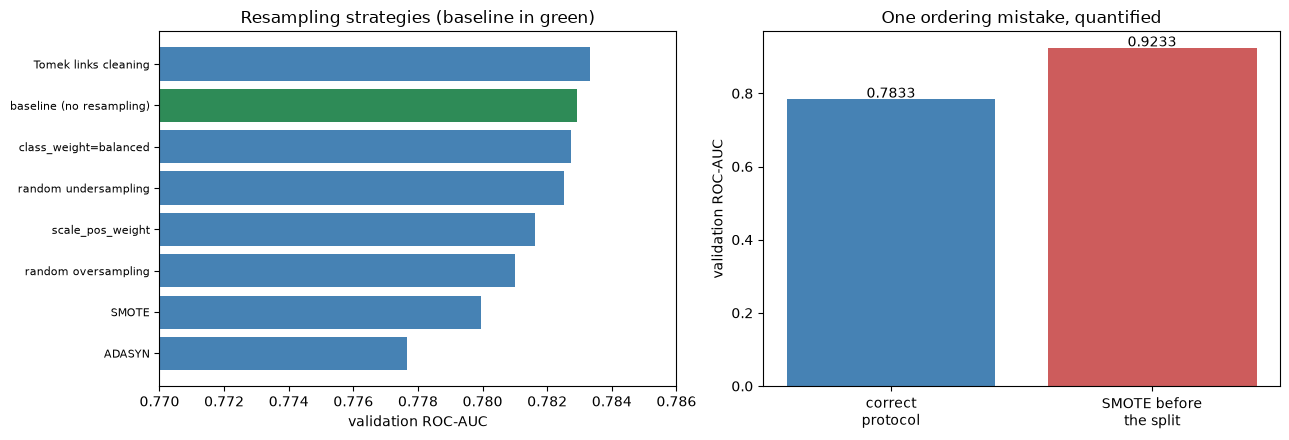

In [3]:
valid = resampling[~resampling["name"].str.contains("INVALID")]
leaky = resampling[resampling["name"].str.contains("INVALID")]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

order = valid.sort_values("roc_auc")
colours = ["seagreen" if "baseline" in n else "steelblue" for n in order["name"]]
axes[0].barh(order["name"], order["roc_auc"], color=colours)
axes[0].set_xlim(0.77, 0.786)
axes[0].set_xlabel("validation ROC-AUC")
axes[0].set_title("Resampling strategies (baseline in green)")
axes[0].tick_params(axis="y", labelsize=8)

if len(leaky):
    axes[1].bar(["correct\nprotocol", "SMOTE before\nthe split"],
                [valid["roc_auc"].max(), leaky["roc_auc"].iloc[0]],
                color=["steelblue", "indianred"])
    axes[1].set_ylabel("validation ROC-AUC")
    axes[1].set_title("One ordering mistake, quantified")
    for i, v in enumerate([valid["roc_auc"].max(), leaky["roc_auc"].iloc[0]]):
        axes[1].text(i, v + 0.005, f"{v:.4f}", ha="center")

plt.tight_layout()
plt.show()

**No resampling strategy improves on the baseline by more than noise**, and SMOTE and ADASYN
are among the worst. At a 22% positive rate the model already sees plenty of defaulters; the
techniques exist for problems one or two orders of magnitude rarer.

The counter-example is the part worth keeping. Applying SMOTE before splitting instead of
after inflates AUC enormously — the same technique, one ordering mistake. It is a plausible
explanation for unusually high figures reported elsewhere on this dataset.

## 2. Do ensembles beat a single tuned model?

Soft voting averages predicted probabilities. Weighted voting favours the stronger members.
Stacking trains a meta-model to combine them, cross-fitted so it does not simply memorise.
Hard voting takes a majority of predicted labels.

In [4]:
ensembles = frame("ensembling").sort_values("roc_auc", ascending=False)
ensembles["vs single model"] = (ensembles["roc_auc"] - REFERENCE).round(4)
ensembles.round(4)

,name,roc_auc,pr_auc,best_f1,balanced_accuracy,brier,seconds,note,vs single model
0,single tuned LightGBM,0.7831,0.5573,0.5458,0.6486,0.1350,7.4,reference,0.0000
4,stacking (logreg meta),0.7824,0.5591,0.5438,0.6509,0.1361,69.6,"meta-model learns how to combine, cross-fitted",-0.0007
3,soft voting (boosters only),0.7820,0.5565,0.5423,0.6503,0.1353,70.5,lgbm + xgb,-0.0012
2,"soft voting (weighted 3,3,1,1)",0.7817,0.5594,0.5421,0.6509,0.1351,23.3,favours the boosted trees,-0.0014
1,soft voting (equal),0.7803,0.5592,0.5418,0.6505,0.1353,21.3,averages predicted probabilities,-0.0028
5,hard voting (majority),0.6455,0.3716,0.4495,0.6455,0.1840,10.4,"labels not probabilities, so AUC is degraded b...",-0.1377


**Nothing beats the single tuned model.** Stacking costs an order of magnitude more compute
to land fractionally below it.

Hard voting is far worse than everything else, and that is expected rather than a bug: it
returns labels, not probabilities, so there is almost nothing left to rank and a ranking
metric collapses. It is kept in the table because the gap demonstrates what AUC actually
measures.

## 3. Were enough model families tried?

In [5]:
families = frame("model_families").sort_values("roc_auc", ascending=False)
families["vs tuned LightGBM"] = (families["roc_auc"] - REFERENCE).round(4)
families.round(4)

,name,roc_auc,pr_auc,best_f1,balanced_accuracy,brier,seconds,note,vs tuned LightGBM
1,GradientBoosting (sklearn),0.7807,0.5536,0.5444,0.6564,0.1352,31.1,the original boosting implementation,-0.0025
3,ExtraTrees,0.7734,0.5551,0.5404,0.6499,0.1361,7.6,randomised splits,-0.0098
2,HistGradientBoosting,0.7724,0.5438,0.5362,0.6465,0.1376,3.0,sklearn's LightGBM equivalent,-0.0108
0,AdaBoost,0.7704,0.5316,0.5317,0.6394,0.1509,18.8,boosted stumps,-0.0128
4,KNN (k=50),0.7691,0.5336,0.5243,0.6475,0.1378,0.9,"instance based, no training",-0.0140
5,Linear SVM (6k subsample),0.7531,0.5162,0.5178,0.6146,0.1706,0.2,"subsampled to 6,000; SVMs scale quadratically",-0.0301


## 4. Does deep learning win?

Four scikit-learn networks of increasing depth, then two PyTorch networks with batch
normalisation, dropout, Adam and early stopping on a held-out slice carved from training.

Grinsztajn et al. (2022) find that tree ensembles outperform neural networks on tabular
data. This is a direct test of that claim on this dataset.

In [6]:
neural = frame("neural_networks").sort_values("roc_auc", ascending=False)
neural["vs tuned LightGBM"] = (neural["roc_auc"] - REFERENCE).round(4)
neural.round(4)

,name,roc_auc,pr_auc,best_f1,balanced_accuracy,brier,seconds,note,vs tuned LightGBM
5,"PyTorch deep (512,256,128,64)",0.7798,0.5536,0.5471,0.6542,0.1357,52.3,"deeper, more dropout",-0.0033
4,"PyTorch (256,128,64)",0.7793,0.5570,0.5462,0.6545,0.1354,47.0,"batch norm, dropout, Adam, early stopping on h...",-0.0038
2,"MLP deep (256,128,64,32)",0.7747,0.5433,0.5395,0.6514,0.1367,44.4,four hidden layers,-0.0085
1,"MLP (128, 64)",0.7714,0.5397,0.5343,0.6490,0.1372,26.1,two hidden layers,-0.0117
3,"MLP wide (512, 256)",0.7694,0.5528,0.5416,0.6442,0.1367,101.1,wide rather than deep,-0.0138
0,MLP shallow (64),0.7677,0.5382,0.5297,0.6555,0.1377,3.7,one hidden layer,-0.0155


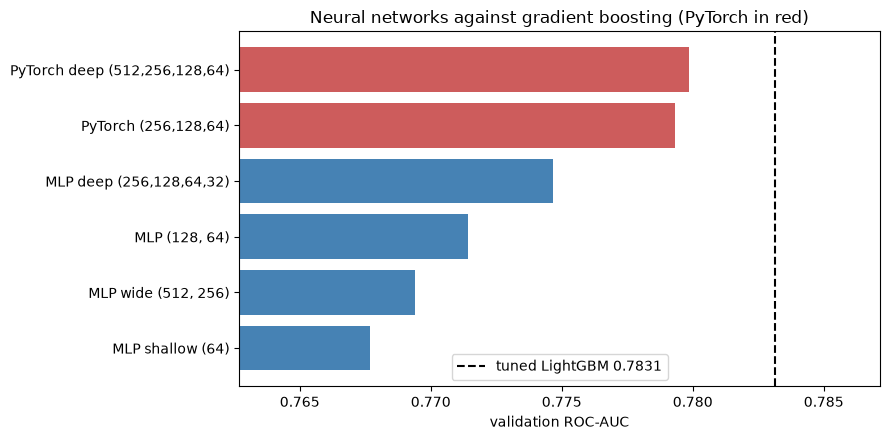

In [7]:
order = neural.sort_values("roc_auc")
colours = ["indianred" if "PyTorch" in n else "steelblue" for n in order["name"]]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(order["name"], order["roc_auc"], color=colours)
ax.axvline(REFERENCE, color="black", ls="--", label=f"tuned LightGBM {REFERENCE:.4f}")
ax.set_xlim(min(order["roc_auc"]) - 0.005, REFERENCE + 0.004)
ax.set_xlabel("validation ROC-AUC")
ax.set_title("Neural networks against gradient boosting (PyTorch in red)")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Do sequence models see what the summaries miss?

Every model above reads flat per-customer statistics. These read the monthly matrix in
order: six timesteps by three channels, with the repayment status embedded rather than
scaled, because -2 (no balance), -1 (paid in full) and 0 (revolving) are categories and -2
is healthier than 0.

Twenty configurations across five architectures, because the booster has seventy tuning
configurations behind it and comparing it against one hand-set network would not be a fair
test. The question that matters is not the network alone, which has no feature engineering
behind it, but whether **blending** it with the booster beats the booster: section 2 stacked
tree models that all saw the same flat features, so a different hypothesis class has never
been tried.

In [8]:
SEQUENCE_RESULTS = PROJECT_ROOT / "backend" / "artifacts" / "sequence_models.json"
if not SEQUENCE_RESULTS.exists():
    raise FileNotFoundError(
        f"{SEQUENCE_RESULTS} not found. Generate it with:\n"
        "    cd backend && python -m app.ml.sequence_models"
    )

sequence = json.loads(SEQUENCE_RESULTS.read_text(encoding="utf-8"))
search = pd.DataFrame(sequence["search"])

print(f"booster validation {sequence['booster']['validation_auc']:.4f}")
search.groupby("architecture")["validation_auc"].agg(["max", "mean"]).sort_values(
    "max", ascending=False).round(4)

booster validation 0.7832


,max,mean
architecture,,
lstm,0.7683,0.7649
cnn,0.7661,0.7643
gru,0.7657,0.7636
bilstm,0.7641,0.7632
attention,0.7581,0.7542


In [9]:
winner, blend = sequence["winner"], sequence["blend"]
print(f"winner: {winner['architecture']}, hidden {winner['hidden']}, "
      f"{winner['layers']} layer(s), dropout {winner['dropout']}")
print(f"rank correlation with the booster: {sequence['rank_correlation_with_booster']:.3f}")

pd.DataFrame({
    "validation_auc": [sequence["booster"]["validation_auc"],
                       sequence["network"]["validation_auc"],
                       blend["validation_auc"]],
    "test_auc": [sequence["booster"]["test_auc"],
                 sequence["network"]["test_auc"],
                 blend["test_auc"]],
}, index=["booster alone", "sequence network",
          f"blend at weight {blend['weight']}"]).round(4)

winner: lstm, hidden 32, 1 layer(s), dropout 0.1
rank correlation with the booster: 0.897


,validation_auc,test_auc
booster alone,0.7832,0.7824
sequence network,0.7679,0.7636
blend at weight 0.05,0.7832,0.7823


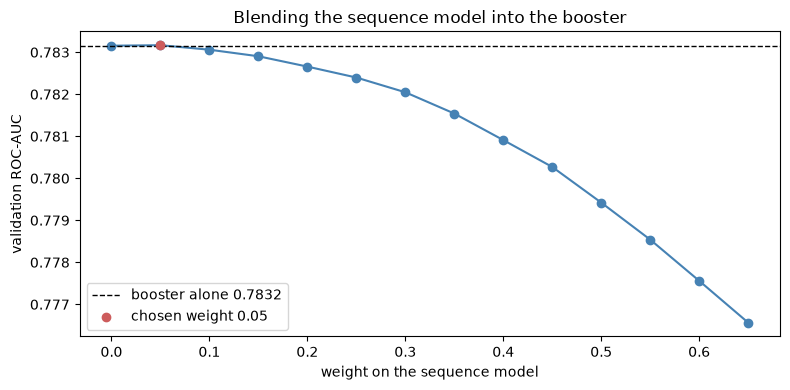

validation gain at the chosen weight: +0.0000
the same weight on test:              -0.0002


In [10]:
sweep = pd.Series({float(w): a for w, a in sequence["blend_sweep_validation"].items()})

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(sweep.index, sweep.to_numpy(), marker="o", color="steelblue")
ax.axhline(sequence["booster"]["validation_auc"], color="black", ls="--", lw=1,
           label=f"booster alone {sequence['booster']['validation_auc']:.4f}")
ax.scatter([blend["weight"]], [blend["validation_auc"]], color="indianred", zorder=5,
           label=f"chosen weight {blend['weight']}")
ax.set_xlabel("weight on the sequence model")
ax.set_ylabel("validation ROC-AUC")
ax.set_title("Blending the sequence model into the booster")
ax.legend()
plt.tight_layout()
plt.show()

# The weight is chosen on validation and then applied once to test. The gap between these
# two numbers is what selecting on the data you report costs.
print(f"validation gain at the chosen weight: {blend['validation_gain']:+.4f}")
print(f"the same weight on test:              {blend['test_gain']:+.4f}")

## 6. Which features are worth including?

Computed by `app.ml.feature_experiments`, which differs from everything above in one
important way: each arm runs the **deployed pipeline end to end** (the three-seed ensemble on
train, the F1-optimal threshold from validation, a refit on train plus validation, then test)
and is **paired across five independent split seeds**.

That matters because the effects here are smaller than a single split can resolve. Measured
once on validation with a train-only fit, the extra columns from notebook 01 looked harmful.
Paired across five splits of the real pipeline they are a small consistent gain. The spread
of the paired *difference*, not the spread of the metric, is what decides.

In [11]:
FEATURE_RESULTS = PROJECT_ROOT / "backend" / "artifacts" / "feature_experiments.json"
if not FEATURE_RESULTS.exists():
    raise FileNotFoundError(
        f"{FEATURE_RESULTS} not found. Generate it with:\n"
        "    cd backend && python -m app.ml.feature_experiments"
    )

feature_studies = json.loads(FEATURE_RESULTS.read_text(encoding="utf-8"))["studies"]
print(f"studies: {list(feature_studies)}")

PAIRED_COLUMNS = ["features", "test_auc", "delta_test_auc", "delta_test_auc_spread",
                  "better_on_splits", "delta_test_f1", "delta_recall_at_alert_rate"]


def paired(study: str) -> pd.DataFrame:
    """One study's arms, reference first, with the paired differences beside them."""
    table = pd.DataFrame(feature_studies[study]["arms"]).T[PAIRED_COLUMNS]
    reference = feature_studies[study]["reference"]
    return pd.concat([table.loc[[reference]], table.drop(index=reference)]).round(4)


paired("additions")

studies: ['additions', 'demographics', 'retuning', 'segmentation', 'selection']


,features,test_auc,delta_test_auc,delta_test_auc_spread,better_on_splits,delta_test_f1,delta_recall_at_alert_rate
served only,46.0,0.7870,0.0000,0.0000,0.0,0.0000,0.0000
+ repayment counts,48.0,0.7870,-0.0001,0.0001,2.0,0.0011,0.0004
+ utilisation slope,47.0,0.7873,0.0003,0.0003,4.0,0.0008,0.0004
+ consecutive delinquency,47.0,0.7870,-0.0000,0.0002,2.0,0.0011,0.0000
+ volatility,49.0,0.7869,-0.0001,0.0004,2.0,0.0017,-0.0004
+ recent vs historical,48.0,0.7869,-0.0001,0.0003,1.0,0.0008,0.0000
+ inferred spending,49.0,0.7873,0.0003,0.0001,5.0,0.0013,0.0006
+ roll-rate transitions,49.0,0.7869,-0.0001,0.0001,1.0,0.0034,-0.0006
+ minimum payment,48.0,0.7870,-0.0000,0.0001,1.0,0.0017,0.0006
+ round-number payments,47.0,0.7869,-0.0001,0.0002,2.0,0.0006,-0.0008


In [12]:
print("What excluding the protected attributes costs:")
display(paired("demographics"))

retuning = feature_studies["retuning"]
print(f"\nGreedy group selection kept: {retuning['selected_groups'] or 'nothing'}")
print(f"deployed hyperparameters, CV on the larger set: {retuning['deployed_cv_auc']:.4f}")
print(f"best of {retuning['configurations']} searched configurations: "
      f"{retuning['best_search_cv_auc']:.4f}")
print(f"re-tuning beats the deployed configuration: {retuning['retuning_beats_deployed']}")

What excluding the protected attributes costs:


,features,test_auc,delta_test_auc,delta_test_auc_spread,better_on_splits,delta_test_f1,delta_recall_at_alert_rate
blind (deployed),46.0,0.7870,0.0000,0.0000,0.0,0.0000,0.0000
+ AGE,47.0,0.7875,0.0004,0.0003,4.0,0.0003,0.0026
+ EDUCATION,47.0,0.7873,0.0002,0.0002,4.0,0.0004,-0.0000
+ SEX,47.0,0.7873,0.0003,0.0004,4.0,-0.0013,-0.0002
+ all four,50.0,0.7882,0.0012,0.0006,5.0,0.0011,0.0028



Greedy group selection kept: ['predictability']
deployed hyperparameters, CV on the larger set: 0.7913
best of 40 searched configurations: 0.7913
re-tuning beats the deployed configuration: False


In [13]:
print("Segmented scorecards, one model per behavioural archetype:")
display(paired("segmentation"))

print("\nAutomated selection, columns ranked by permutation importance on validation:")
display(paired("selection"))

Segmented scorecards, one model per behavioural archetype:


,features,test_auc,delta_test_auc,delta_test_auc_spread,better_on_splits,delta_test_f1,delta_recall_at_alert_rate
global,46.0,0.7870,0.0000,0.0000,0.0,0.0000,0.0000
global + segment,47.0,0.7870,-0.0001,0.0002,1.0,-0.0003,-0.0006
per-segment models,46.0,0.7837,-0.0033,0.0018,1.0,-0.0011,-0.0050



Automated selection, columns ranked by permutation importance on validation:


,features,test_auc,delta_test_auc,delta_test_auc_spread,better_on_splits,delta_test_f1,delta_recall_at_alert_rate
all columns,70.0,0.7876,0.0000,0.0000,0.0,0.0000,0.0000
top 10,10.0,0.7848,-0.0028,0.0014,0.0,-0.0045,-0.0032
top 20,20.0,0.7876,-0.0000,0.0008,3.0,-0.0037,-0.0022
top 30,30.0,0.7876,-0.0000,0.0005,4.0,-0.0020,-0.0014
top 40,40.0,0.7875,-0.0001,0.0007,3.0,-0.0047,-0.0006
top 50,50.0,0.7874,-0.0002,0.0003,2.0,-0.0024,-0.0006
top 60,60.0,0.7876,0.0000,0.0003,2.0,0.0013,-0.0014
positive importance only,44.4,0.7876,-0.0000,0.0002,2.0,-0.0043,0.0000


## Everything together

In [14]:
combined = pd.concat(
    [frame(name).assign(study=name) for name in studies], ignore_index=True
)
combined = combined[~combined["name"].str.contains("INVALID")]
combined = combined.sort_values("roc_auc", ascending=False).reset_index(drop=True)

print(f"{len(combined)} valid configurations across {len(studies)} studies\n")
print(f"best   {combined.iloc[0]['roc_auc']:.4f}  {combined.iloc[0]['name']}")
print(f"worst  {combined.iloc[-1]['roc_auc']:.4f}  {combined.iloc[-1]['name']}")
print(f"spread {combined['roc_auc'].max() - combined['roc_auc'].min():.4f}")

top = combined.head(12)[["study", "name", "roc_auc", "best_f1", "seconds"]]
top.round(4)

26 valid configurations across 4 studies

best   0.7833  Tomek links cleaning
worst  0.6455  hard voting (majority)
spread 0.1379


,study,name,roc_auc,best_f1,seconds
0,resampling,Tomek links cleaning,0.7833,0.5414,3.6
1,ensembling,single tuned LightGBM,0.7831,0.5458,7.4
2,resampling,baseline (no resampling),0.7829,0.5456,3.0
3,resampling,class_weight=balanced,0.7827,0.5453,2.9
4,resampling,random undersampling,0.7825,0.5528,1.4
5,ensembling,stacking (logreg meta),0.7824,0.5438,69.6
6,ensembling,soft voting (boosters only),0.7820,0.5423,70.5
7,ensembling,"soft voting (weighted 3,3,1,1)",0.7817,0.5421,23.3
8,resampling,scale_pos_weight,0.7816,0.5473,2.5
9,resampling,random oversampling,0.7810,0.5447,3.4


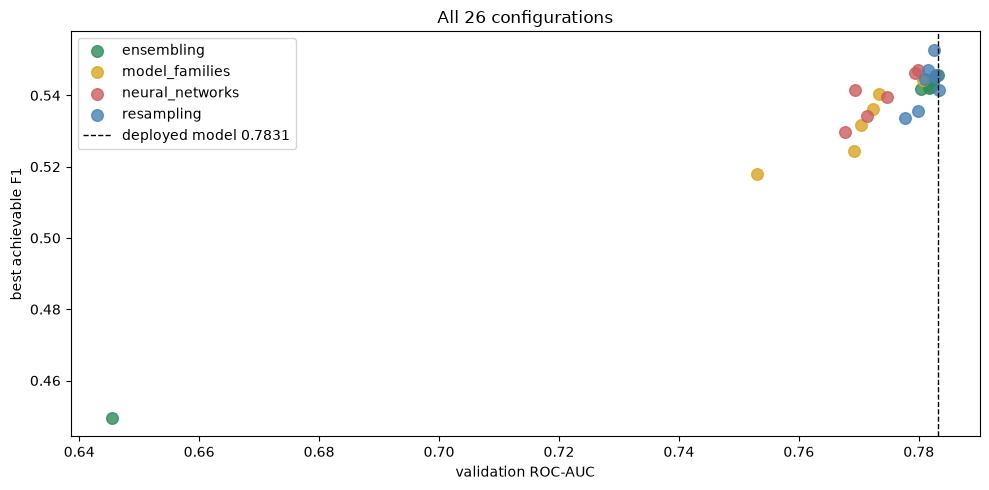

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
palette = {"resampling": "steelblue", "ensembling": "seagreen",
           "model_families": "goldenrod", "neural_networks": "indianred"}
for study, group in combined.groupby("study"):
    ax.scatter(group["roc_auc"], group["best_f1"], s=70, alpha=0.8,
               color=palette.get(study, "grey"), label=study)
ax.axvline(REFERENCE, color="black", ls="--", lw=1,
           label=f"deployed model {REFERENCE:.4f}")
ax.set_xlabel("validation ROC-AUC"); ax.set_ylabel("best achievable F1")
ax.set_title(f"All {len(combined)} configurations")
ax.legend()
plt.tight_layout()
plt.show()

## Conclusion

Six independent directions: rebalancing the classes, combining models, changing model family,
adding network depth, reading the months as a sequence, and changing the feature set. Two of
them move the number at all, and both move it by less than a hundredth of what separates a
good model from a bad one.

| Direction | Result |
|---|---|
| Class balancing | nothing beats the baseline by more than noise |
| Ensembling | a single tuned model beats voting and stacking |
| Model families | nothing within 0.002 of the deployed model |
| Network depth | best 0.7798, below the booster |
| Sequence models | best 0.7683 alone; blending worth −0.0002 on test |
| **Extra features** | **+0.0006 AUC, consistent on 5/5 splits** |
| Segmented scorecards | −0.0033; one model per archetype is worse |
| Automated selection | 20 columns match all 70; none beats them |

Two things in that table are worth more than the numbers.

**The extra features do help, slightly.** Paired across five splits of the full deployed
pipeline they gain +0.0006 AUC and +0.0026 F1, positive on every split. The same comparison on
a single validation split said −0.0015. Nothing changed except the measurement, which is the
point: the effects remaining in this dataset are smaller than one split can resolve, and the
spread across splits here is enormous by comparison — every arm scores about 0.804 on split 777
and about 0.775 on split 2024. Only the paired difference means anything.

**Selection says the same thing from the other side.** The twenty highest-ranked columns match
all seventy, and the ten highest lose 0.0028. There is no subset that beats the whole, and no
penalty for dropping fifty columns. The information saturates early.

Everything else is a negative result, and together they say the limit is a property of the data
rather than of the modelling effort. Six months of repayment status, bills and amounts paid
support about 0.78 AUC about next month, whether those months are summarised by hand, fed to a
recurrent network in order, resampled, reweighted, recombined, or re-tuned. That is a stronger
claim than any single number here, and it is the one a reader should want before accepting the
headline result.